# Procesamiento de señales · Muestreo y espectro

Señales digitales sintéticas con `numpy` y `scipy.signal`: cómo se generan a partir de una frecuencia de muestreo, cuánta potencia tienen y qué frecuencias contienen. Se programa la **transformada discreta de Fourier** a mano, con coste $O(n^2)$, y una FFT recursiva en $O(n \log n)$, y se comparan con `np.fft`. Después, el espectro de amplitud con `rfft` y `rfftfreq`, la resolución en frecuencia, el **aliasing** y el teorema de Nyquist, la fuga espectral y la ventana de Hann, la serie de Fourier de una onda cuadrada, el teorema de Parseval y una compresión que descarta los coeficientes pequeños. Las comprobaciones se hacen sobre los valores calculados, no sobre los dibujos. Ideas de [Think DSP](https://greenteapress.com/wp/think-dsp/) y de la [guía de `scipy.signal`](https://docs.scipy.org/doc/scipy/tutorial/signal.html).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal

## 1. Generar señales muestreadas

Con una frecuencia de muestreo de 1000 Hz y un segundo de duración, generar un seno de 5 Hz y amplitud 2, una suma de tonos de 50 y 120 Hz, una onda cuadrada de 4 Hz (`signal.square`) y ruido gaussiano de desviación 0,5 con semilla fija. Dibujar las cuatro y comprobar el número de muestras, el periodo del seno y los valores de la cuadrada.

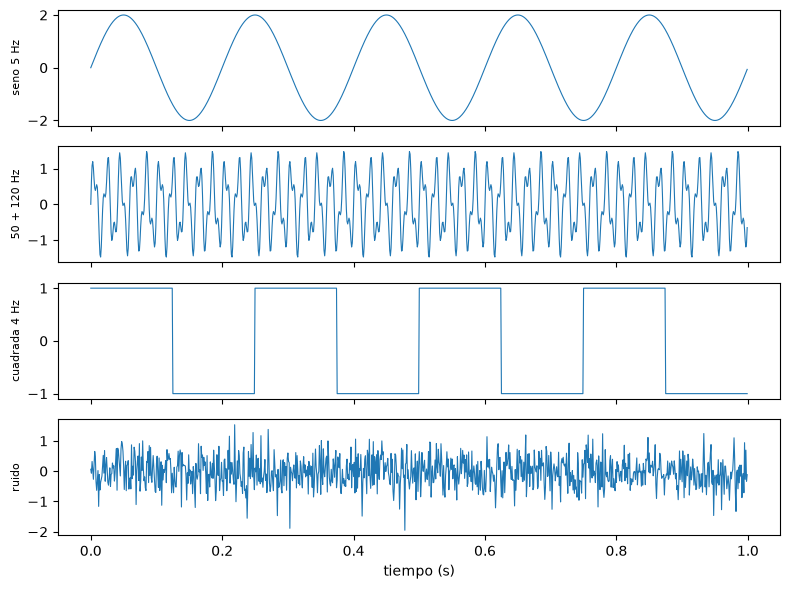

Muestras: 1000; muestras por periodo del seno: 200; desviación del ruido: 0.488


In [2]:
fs, duracion = 1000, 1.0
t = np.arange(int(fs * duracion)) / fs
rng = np.random.default_rng(0)

seno = 2 * np.sin(2 * np.pi * 5 * t)
tonos = np.sin(2 * np.pi * 50 * t) + 0.5 * np.sin(2 * np.pi * 120 * t)
cuadrada = signal.square(2 * np.pi * 4 * t)
ruido = rng.normal(0, 0.5, t.size)

fig, ejes = plt.subplots(4, 1, figsize=(8, 6), sharex=True)
for ax, (nombre, x) in zip(ejes, [("seno 5 Hz", seno), ("50 + 120 Hz", tonos), ("cuadrada 4 Hz", cuadrada),
                                  ("ruido", ruido)]):
    ax.plot(t, x, lw=0.8)
    ax.set_ylabel(nombre, fontsize=8)
ejes[-1].set_xlabel("tiempo (s)")
fig.tight_layout()
plt.show()

periodo = fs // 5
print(f"Muestras: {t.size}; muestras por periodo del seno: {periodo}; desviación del ruido: {ruido.std():.3f}")
assert t.size == 1000 and np.allclose(seno[:-periodo], seno[periodo:])
assert set(np.unique(cuadrada)) == {-1.0, 1.0} and abs(ruido.std() - 0.5) < 0.05

## 2. Potencia, valor eficaz y relación señal-ruido

Calcular el valor eficaz (RMS) de las señales anteriores y comprobar los valores teóricos: $A/\sqrt{2}$ para un seno y 1 para la cuadrada. Después, añadir al seno ruido con la desviación justa para una relación señal-ruido de 10 dB y medir la SNR obtenida.

In [3]:
def rms(x):
    return np.sqrt(np.mean(x ** 2))


def snr_db(limpia, ruidosa):
    return 10 * np.log10(np.mean(limpia ** 2) / np.mean((ruidosa - limpia) ** 2))


for nombre, x in [("seno", seno), ("tonos", tonos), ("cuadrada", cuadrada), ("ruido", ruido)]:
    print(f"{nombre:9} RMS = {rms(x):.4f}")
assert np.isclose(rms(seno), 2 / np.sqrt(2)) and np.isclose(rms(cuadrada), 1)
assert np.isclose(rms(tonos), np.sqrt(0.5 + 0.125))

objetivo = 10
sigma = np.sqrt(np.mean(seno ** 2) / 10 ** (objetivo / 10))
ruidosa = seno + np.random.default_rng(1).normal(0, sigma, t.size)
print(f"Desviación del ruido: {sigma:.3f}; SNR medida: {snr_db(seno, ruidosa):.2f} dB")
assert abs(snr_db(seno, ruidosa) - objetivo) < 0.5

seno      RMS = 1.4142
tonos     RMS = 0.7906
cuadrada  RMS = 1.0000
ruido     RMS = 0.4890
Desviación del ruido: 0.447; SNR medida: 10.11 dB


## 3. DFT a mano

Programar la transformada discreta de Fourier $X_k = \sum_{n=0}^{N-1} x_n\, e^{-2\pi i k n / N}$ de dos formas, con dos bucles y con una matriz de exponenciales, y su inversa. Comprobar con una señal aleatoria de 64 muestras que coinciden con `np.fft.fft` y `np.fft.ifft`.

In [4]:
def dft_bucles(x):
    N = len(x)
    X = []
    for k in range(N):
        X.append(sum(x[n] * np.exp(-2j * np.pi * k * n / N) for n in range(N)))
    return np.array(X)


def dft_matriz(x):
    N = len(x)
    n = np.arange(N)
    return np.exp(-2j * np.pi * np.outer(n, n) / N) @ x


def idft_matriz(X):
    N = len(X)
    n = np.arange(N)
    return np.exp(2j * np.pi * np.outer(n, n) / N) @ X / N


x = np.random.default_rng(2).normal(size=64)
X = np.fft.fft(x)
print("X[0] = suma de las muestras:", np.round(X[0].real, 6), np.round(x.sum(), 6))
print("Simetría de una señal real, X[5] y X[59]:", np.round(X[5], 3), np.round(X[59], 3))
assert np.allclose(dft_bucles(x), X) and np.allclose(dft_matriz(x), X)
assert np.allclose(idft_matriz(X), x) and np.allclose(X[1:], np.conj(X[1:][::-1]))

X[0] = suma de las muestras: 4.935603 4.935603
Simetría de una señal real, X[5] y X[59]: (-6.643+2.321j) (-6.643-2.321j)


## 4. FFT recursiva y su coste

Programar la FFT de Cooley-Tukey para longitudes potencia de 2: la DFT de $N$ puntos se obtiene de las DFT de las muestras pares e impares, de $N/2$ puntos cada una. Contar las multiplicaciones complejas de la DFT directa ($N^2$) y de la FFT ($\frac{N}{2}\log_2 N$) para varios tamaños y comprobar el resultado con `np.fft.fft`.

In [5]:
def fft_recursiva(x, contador):
    N = len(x)
    if N == 1:
        return np.array(x, dtype=complex)
    pares = fft_recursiva(x[0::2], contador)
    impares = fft_recursiva(x[1::2], contador)
    giro = np.exp(-2j * np.pi * np.arange(N // 2) / N) * impares
    contador[0] += N // 2
    return np.concatenate([pares + giro, pares - giro])


print(f"{'N':>6} {'DFT N²':>12} {'FFT':>10} {'ahorro':>8}")
for p in range(3, 14, 2):
    N = 2 ** p
    x = np.random.default_rng(p).normal(size=N)
    contador = [0]
    X = fft_recursiva(x, contador)
    assert np.allclose(X, np.fft.fft(x)) and contador[0] == N // 2 * p
    print(f"{N:6} {N * N:12,} {contador[0]:10,} {N * N / contador[0]:7.0f}×")

     N       DFT N²        FFT   ahorro
     8           64         12       5×
    32        1,024         80      13×
   128       16,384        448      37×
   512      262,144      2,304     114×
  2048    4,194,304     11,264     372×
  8192   67,108,864     53,248    1260×


## 5. Espectro de amplitud con `rfft` y `rfftfreq`

Para una señal real basta la mitad positiva del espectro. Calcular con `np.fft.rfft` y `np.fft.rfftfreq` el espectro de amplitud de la suma de tonos de 50 y 120 Hz con ruido, escalado para que cada pico mida la amplitud del tono ($2|X_k|/N$), localizar los picos con `signal.find_peaks` y comprobar frecuencias y amplitudes.

  50.0 Hz  amplitud 0.991
 120.0 Hz  amplitud 0.540


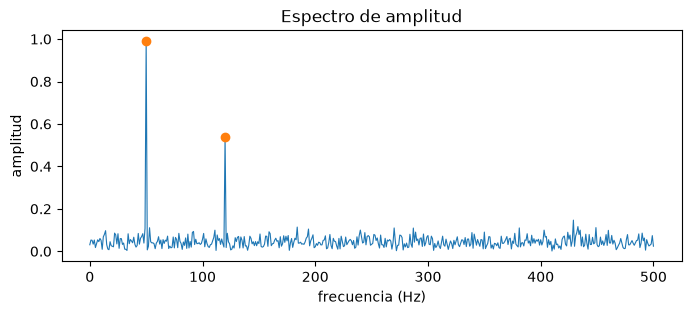

In [6]:
def espectro(x, fs):
    frecuencias = np.fft.rfftfreq(len(x), d=1 / fs)
    amplitudes = 2 * np.abs(np.fft.rfft(x)) / len(x)
    amplitudes[0] /= 2
    return frecuencias, amplitudes


senal = tonos + np.random.default_rng(3).normal(0, 0.8, t.size)
f, A = espectro(senal, fs)
picos, _ = signal.find_peaks(A, height=0.3)
for p in picos:
    print(f"{f[p]:6.1f} Hz  amplitud {A[p]:.3f}")

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(f, A, lw=0.8)
ax.plot(f[picos], A[picos], "o")
ax.set(xlabel="frecuencia (Hz)", ylabel="amplitud", title="Espectro de amplitud")
plt.show()
assert list(f[picos]) == [50, 120] and np.allclose(A[picos], [1, 0.5], atol=0.1)

## 6. Resolución en frecuencia

La separación entre las frecuencias de la DFT es $\Delta f = f_s / N = 1 / T$: depende de la duración, no de la frecuencia de muestreo. Analizar dos tonos de 100 y 103 Hz durante 0,2 s y durante 2 s y comprobar que solo con la duración larga aparecen dos picos separados.

T = 0.2 s: Δf = 5.0 Hz; picos en [100.]
T = 2.0 s: Δf = 0.5 Hz; picos en [100. 103.]


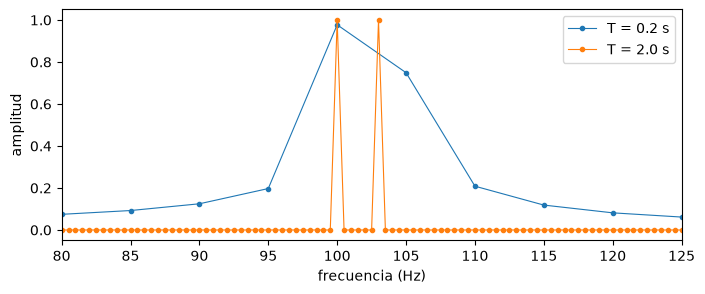

In [7]:
fig, ax = plt.subplots(figsize=(8, 3))
for T in [0.2, 2.0]:
    tt = np.arange(int(fs * T)) / fs
    x = np.sin(2 * np.pi * 100 * tt) + np.sin(2 * np.pi * 103 * tt)
    f, A = espectro(x, fs)
    picos, _ = signal.find_peaks(A, height=0.5)
    print(f"T = {T} s: Δf = {f[1]:.1f} Hz; picos en {f[picos]}")
    ax.plot(f, A, ".-", lw=0.8, label=f"T = {T} s")
    assert len(picos) == (1 if T == 0.2 else 2)
ax.set(xlim=(80, 125), xlabel="frecuencia (Hz)", ylabel="amplitud")
ax.legend()
plt.show()

## 7. Aliasing

Al muestrear a $f_s$, un tono de frecuencia $f$ es indistinguible de otro de frecuencia $|f - f_s \cdot \mathrm{round}(f / f_s)|$. Escribir esa fórmula, muestrear a 100 Hz cosenos de 30, 70, 130 y 170 Hz y comprobar que las muestras son idénticas y que el pico del espectro está siempre en la frecuencia aparente. Dibujar el coseno de 70 Hz, sus muestras y el de 30 Hz que pasa por ellas.

  30 Hz -> se ve a   30 Hz (fórmula: 30 Hz)
  70 Hz -> se ve a   30 Hz (fórmula: 30 Hz)
 130 Hz -> se ve a   30 Hz (fórmula: 30 Hz)
 170 Hz -> se ve a   30 Hz (fórmula: 30 Hz)
 260 Hz -> se ve a   40 Hz (fórmula: 40 Hz)


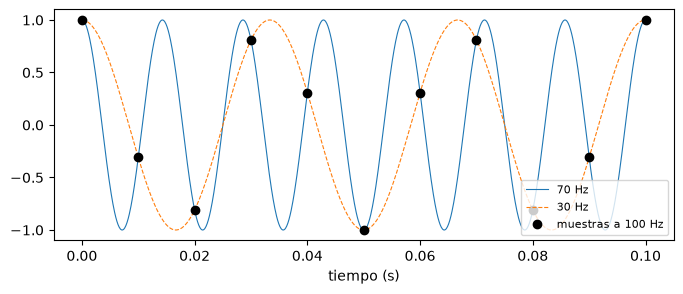

In [8]:
def frecuencia_aparente(f, fs):
    return abs(f - fs * round(f / fs))


fs_baja = 100
n = np.arange(100)
referencia = np.cos(2 * np.pi * 30 * n / fs_baja)
for f0 in [30, 70, 130, 170, 260]:
    muestras = np.cos(2 * np.pi * f0 * n / fs_baja)
    f, A = espectro(muestras, fs_baja)
    print(f"{f0:4} Hz -> se ve a {f[A.argmax()]:4.0f} Hz (fórmula: {frecuencia_aparente(f0, fs_baja)} Hz)")
    assert f[A.argmax()] == frecuencia_aparente(f0, fs_baja)
    if frecuencia_aparente(f0, fs_baja) == 30:
        assert np.allclose(muestras, referencia)

fino = np.linspace(0, 0.1, 1000)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(fino, np.cos(2 * np.pi * 70 * fino), lw=0.8, label="70 Hz")
ax.plot(fino, np.cos(2 * np.pi * 30 * fino), "--", lw=0.8, label="30 Hz")
ax.plot(n[:11] / fs_baja, referencia[:11], "ko", label="muestras a 100 Hz")
ax.set(xlabel="tiempo (s)")
ax.legend(loc="lower right", fontsize=8)
plt.show()

## 8. Teorema de Nyquist y reconstrucción

Una señal con componentes de 3 y 7 Hz se puede reconstruir sin error a partir de sus muestras si $f_s > 14$ Hz, con la interpolación de Whittaker-Shannon $x(t) = \sum_n x_n\, \mathrm{sinc}(f_s t - n)$. Muestrearla 10 s a 20 Hz y a 10 Hz, reconstruirla en una malla fina y comparar el error en el tramo central (los extremos sufren por tener pocas muestras a un lado).

fs = 20 Hz: error máximo en [4, 6] s = 0.000
fs = 10 Hz: error máximo en [4, 6] s = 1.154


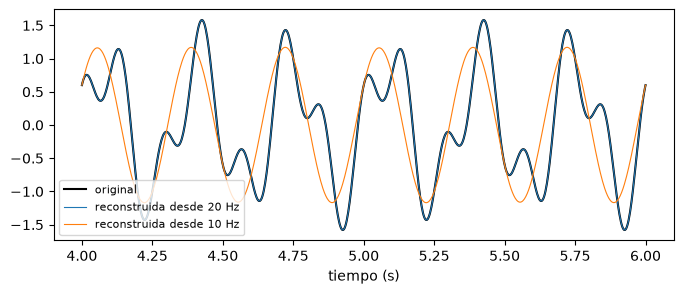

In [9]:
def original(tt):
    return np.sin(2 * np.pi * 3 * tt) + 0.6 * np.cos(2 * np.pi * 7 * tt)


def reconstruir(muestras, fs, tt):
    n = np.arange(len(muestras))
    return np.sinc(fs * tt[:, None] - n) @ muestras


malla = np.linspace(4, 6, 801)
errores = {}
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(malla, original(malla), "k", lw=1.5, label="original")
for fs_m in [20, 10]:
    muestras = original(np.arange(10 * fs_m) / fs_m)
    rec = reconstruir(muestras, fs_m, malla)
    errores[fs_m] = np.max(np.abs(rec - original(malla)))
    print(f"fs = {fs_m} Hz: error máximo en [4, 6] s = {errores[fs_m]:.3f}")
    ax.plot(malla, rec, lw=0.8, label=f"reconstruida desde {fs_m} Hz")
ax.set(xlabel="tiempo (s)")
ax.legend(fontsize=8)
plt.show()
assert errores[20] < 0.1 < 1 < errores[10]

## 9. Fuga espectral

Si un tono no completa un número entero de periodos en la ventana analizada, su energía se reparte por muchas frecuencias. Comparar el espectro en dB de un tono de 10 Hz y otro de 10,5 Hz en 1 s, con ventana rectangular y con ventana de Hann, y medir qué fracción de la energía cae a más de 3 bins del pico.

   10 Hz, rectangular  energía fuera de ±3 bins: 0.00e+00
   10 Hz, Hann         energía fuera de ±3 bins: 0.00e+00
 10.5 Hz, rectangular  energía fuera de ±3 bins: 5.26e-02
 10.5 Hz, Hann         energía fuera de ±3 bins: 7.20e-05


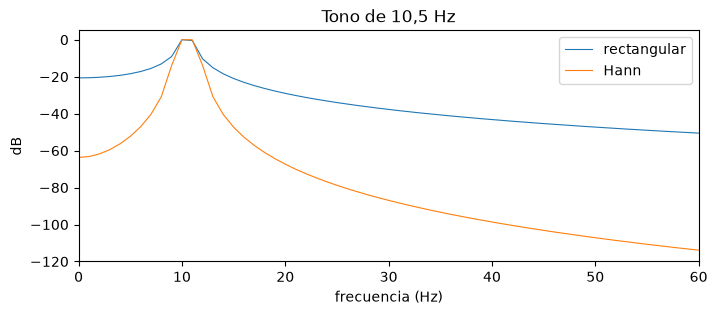

In [10]:
def fuga(x, ventana):
    X = np.abs(np.fft.rfft(x * ventana)) ** 2
    k = X.argmax()
    return 1 - X[max(k - 3, 0):k + 4].sum() / X.sum()


N = 1000
tt = np.arange(N) / N
rect, hann = np.ones(N), signal.windows.hann(N, sym=False)
fugas = {}
fig, ax = plt.subplots(figsize=(8, 3))
for f0 in [10, 10.5]:
    x = np.sin(2 * np.pi * f0 * tt)
    for nombre, w in [("rectangular", rect), ("Hann", hann)]:
        fugas[f0, nombre] = fuga(x, w)
        print(f"{f0:5} Hz, {nombre:12} energía fuera de ±3 bins: {fugas[f0, nombre]:.2e}")
        if f0 == 10.5:
            X = np.abs(np.fft.rfft(x * w))
            ax.plot(np.fft.rfftfreq(N, 1 / N), 20 * np.log10(X / X.max() + 1e-12), lw=0.8, label=nombre)
ax.set(xlim=(0, 60), ylim=(-120, 5), xlabel="frecuencia (Hz)", ylabel="dB", title="Tono de 10,5 Hz")
ax.legend()
plt.show()
assert fugas[10, "rectangular"] < 1e-20 and fugas[10.5, "rectangular"] > 0.01
assert fugas[10.5, "Hann"] < fugas[10.5, "rectangular"] / 100

## 10. La ventana de Hann y su corrección de amplitud

Construir a mano la ventana de Hann periódica $w_n = \frac{1}{2} - \frac{1}{2}\cos(2\pi n / N)$ y compararla con `signal.windows.hann(N, sym=False)`. Al enventanar, el pico baja; corregirlo dividiendo por $\sum w_n$ en lugar de por $N$. Medir además la pérdida en el peor caso (tono a medio bin) con cada ventana y compararla con los valores teóricos: $2/\pi$ para la rectangular y $8/(3\pi)$ para la de Hann.

In [11]:
def hann_a_mano(N):
    return 0.5 - 0.5 * np.cos(2 * np.pi * np.arange(N) / N)


def amplitud_pico(x, w):
    return 2 * np.abs(np.fft.rfft(x * w)).max() / w.sum()


assert np.allclose(hann_a_mano(N), hann)
print(f"Ganancia coherente de Hann (media de la ventana): {hann.mean():.3f}")
for f0 in [100, 100.5]:  # lejos de 0 Hz para que no interfiera la imagen negativa
    x = 3 * np.sin(2 * np.pi * f0 * tt)
    r, h = amplitud_pico(x, rect) / 3, amplitud_pico(x, hann) / 3
    print(f"{f0:5} Hz: amplitud medida / real con rectangular {r:.3f}, con Hann {h:.3f}")
assert np.isclose(amplitud_pico(3 * np.sin(2 * np.pi * 10 * tt), hann), 3)
assert np.isclose(r, 2 / np.pi, atol=0.01) and np.isclose(h, 8 / (3 * np.pi), atol=0.01)

Ganancia coherente de Hann (media de la ventana): 0.500
  100 Hz: amplitud medida / real con rectangular 1.000, con Hann 1.000
100.5 Hz: amplitud medida / real con rectangular 0.638, con Hann 0.849


## 11. Serie de Fourier de una onda cuadrada

Una onda cuadrada de amplitud 1 solo tiene armónicos impares, de amplitud $\frac{4}{\pi k}$. Comprobarlo con el espectro de una cuadrada de 5 Hz y reconstruirla con sumas parciales de 1, 3 y 25 armónicos impares. Con muchos términos, la suma sobrepasa el salto un 9 % de su altura (fenómeno de Gibbs): comprobar que el máximo se acerca a $1{,}179$.

  k  f (Hz)   medida   4/(πk)
  1       5   1.2733   1.2732
  2      10   0.0000   0.0000
  3      15   0.4246   0.4244
  4      20   0.0000   0.0000
  5      25   0.2549   0.2546
  6      30   0.0000   0.0000
  7      35   0.1823   0.1819


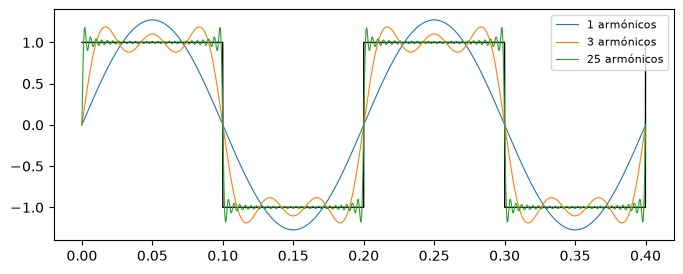

Máximo con 200 armónicos: 1.1790


In [12]:
f, A = espectro(cuadrada_5 := signal.square(2 * np.pi * 5 * t), fs)
print(f"{'k':>3} {'f (Hz)':>7} {'medida':>8} {'4/(πk)':>8}")
for k in range(1, 8):
    i = np.searchsorted(f, 5 * k)
    teorica = 4 / (np.pi * k) if k % 2 else 0
    print(f"{k:3} {f[i]:7.0f} {A[i]:8.4f} {teorica:8.4f}")
    assert abs(A[i] - teorica) < 0.01


def suma_parcial(tt, terminos, f0=5):
    return sum(4 / (np.pi * k) * np.sin(2 * np.pi * k * f0 * tt) for k in range(1, 2 * terminos, 2))


fino = np.linspace(0, 0.4, 4000)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(fino, signal.square(2 * np.pi * 5 * fino), "k", lw=1)
for m in [1, 3, 25]:
    ax.plot(fino, suma_parcial(fino, m), lw=0.8, label=f"{m} armónicos")
ax.legend(fontsize=8, loc="upper right")
plt.show()
maximo = suma_parcial(np.linspace(0, 0.01, 20000), 200).max()
print(f"Máximo con 200 armónicos: {maximo:.4f}")
assert abs(maximo - 1.179) < 0.01

## 12. Teorema de Parseval

La energía de una señal es la misma en el tiempo y en la frecuencia: $\sum |x_n|^2 = \frac{1}{N}\sum |X_k|^2$. Comprobarlo con señales aleatorias de varias longitudes y con las señales del primer ejercicio, y usarlo para repartir la energía de la suma de tonos con ruido entre sus picos.

In [13]:
for N in [7, 64, 1000, 4097]:
    x = np.random.default_rng(N).normal(size=N)
    assert np.isclose(np.sum(x ** 2), np.sum(np.abs(np.fft.fft(x)) ** 2) / N)
for x in [seno, tonos, cuadrada, ruido]:
    assert np.isclose(np.sum(x ** 2), np.sum(np.abs(np.fft.fft(x)) ** 2) / len(x))

X2 = np.abs(np.fft.fft(senal)) ** 2 / len(senal)
fr = np.fft.fftfreq(len(senal), 1 / fs)
total = X2.sum()
for f0 in [50, 120]:
    parte = X2[np.isclose(np.abs(fr), f0)].sum()
    print(f"Energía en ±{f0} Hz: {parte / total:6.1%}")
print(f"Resto (ruido): {1 - X2[np.isin(np.abs(fr), [50, 120])].sum() / total:6.1%}")

Energía en ±50 Hz:  38.3%
Energía en ±120 Hz:  11.4%
Resto (ruido):  50.4%


## 13. Compresión quitando coeficientes pequeños

Comprimir una señal guardando solo una fracción de los coeficientes de `rfft` (los de mayor módulo) y poniendo el resto a cero. Medir el error relativo de la reconstrucción con `irfft` según el porcentaje guardado para una señal tonal con un poco de ruido y para la onda cuadrada, y dibujar ambas curvas. Comprobar que el error baja al guardar más coeficientes y que la señal tonal se comprime mucho mejor: con muy pocos coeficientes, lo que queda de error es casi solo el ruido. La cuadrada muestreada tiene un número finito de armónicos (los impares hasta la frecuencia de Nyquist), así que al guardarlos todos se recupera exacta.

 guardado    tonal  cuadrada
     0.5%    0.065     0.258
     1.0%    0.064     0.200
     2.0%    0.063     0.141
     5.0%    0.059     0.084
    10.0%    0.054     0.041
    20.0%    0.046     0.000
    50.0%    0.025     0.000


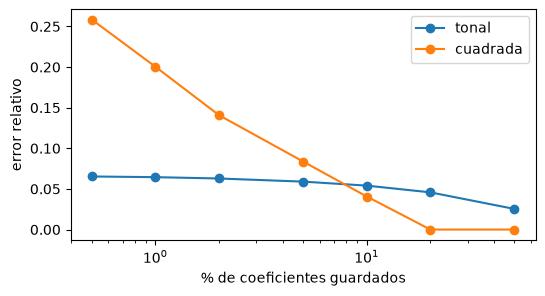

In [14]:
def comprimir(x, fraccion):
    X = np.fft.rfft(x)
    guardar = max(1, int(round(fraccion * X.size)))
    umbral = np.sort(np.abs(X))[-guardar]
    return np.fft.irfft(np.where(np.abs(X) >= umbral, X, 0), n=len(x))


def error_relativo(x, y):
    return np.linalg.norm(x - y) / np.linalg.norm(x)


tonal = (np.sin(2 * np.pi * 7 * t) + 0.4 * np.sin(2 * np.pi * 31 * t) + 0.2 * np.cos(2 * np.pi * 88 * t)
         + np.random.default_rng(4).normal(0, 0.05, t.size))
fracciones = [0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5]
curvas = {nombre: [error_relativo(x, comprimir(x, q)) for q in fracciones]
          for nombre, x in [("tonal", tonal), ("cuadrada", cuadrada)]}
print(f"{'guardado':>9} {'tonal':>8} {'cuadrada':>9}")
for q, e1, e2 in zip(fracciones, curvas["tonal"], curvas["cuadrada"]):
    print(f"{q:9.1%} {e1:8.3f} {e2:9.3f}")

fig, ax = plt.subplots(figsize=(6, 3))
for nombre, errores in curvas.items():
    ax.semilogx([100 * q for q in fracciones], errores, "o-", label=nombre)
ax.set(xlabel="% de coeficientes guardados", ylabel="error relativo")
ax.legend()
plt.show()
for errores in curvas.values():
    assert all(a >= b - 1e-12 for a, b in zip(errores, errores[1:]))
assert curvas["tonal"][1] < 0.1 < curvas["cuadrada"][1]